# 1 - Cleaning and EDA

Sales data of Wide World Importers (2013 - 2016). Same data as the midterm.

Goal of the project: understand the sales and predict if a sale line will be **High Profit** or not.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Raw data

In [2]:
raw = pd.read_excel("../data/raw/Data.xlsx", sheet_name=None)
sales_raw = raw["FactSale"]
items_raw = raw["DimStockItem"]
sales_raw.shape

(26397, 21)

In [3]:
sales_raw.head()

,Sale Key,City Key,Customer Key,Bill To Customer Key,Stock Item Key,Invoice Date Key,Delivery Date Key,Salesperson Key,WWI Invoice ID,Description,...,Quantity,Unit Price,Tax Rate,Total Excluding Tax,Tax Amount,Profit,Total Including Tax,Total Dry Items,Total Chiller Items,Lineage Key
0,49265,41568,0,0,204,2013-10-22,2013-10-23,83,15189,DBA joke mug - mind if I join you? (White),...,6,13,15,78,11.7,51.0,89.7,6,0,11
1,49372,48937,0,0,173,2013-10-22,2013-10-23,83,15218,Developer joke mug - a foo walks into a bar (B...,...,6,13,15,78,11.7,51.0,89.7,6,0,11
2,50379,91464,0,0,174,2013-10-28,2013-10-29,70,15525,Developer joke mug - a foo walks into a bar (W...,...,6,13,15,78,11.7,51.0,89.7,6,0,11
3,51852,48937,0,0,171,2013-11-06,2013-11-07,74,15986,Developer joke mug - this code was generated b...,...,6,13,15,78,11.7,51.0,89.7,6,0,11
4,52374,89925,0,0,203,2013-11-08,2013-11-09,39,16138,DBA joke mug - mind if I join you? (Black),...,6,13,15,78,11.7,51.0,89.7,6,0,11


### Missing values

In [4]:
for name in ["FactSale", "DimStockItem", "DimCustomer", "DimEmployee"]:
    m = raw[name].isnull().sum()
    print(name, m[m > 0].to_dict())

FactSale {'Delivery Date Key': 13}
DimStockItem {'Color': 312, 'Selling Package': 1, 'Buying Package': 1, 'Brand': 605, 'Size': 204, 'Barcode': 656, 'Photo': 672, 'Discount': 672}
DimCustomer {'Bill To Customer': 1, 'Category': 1, 'Buying Group': 1, 'Primary Contact': 1, 'Postal Code': 1}
DimEmployee {'Preferred Name': 1, 'Photo': 212}


### Duplicates

In [5]:
sales_raw.drop(columns='Sale Key').duplicated().sum()

np.int64(0)

### Data types
Unit Price and Total Excluding Tax are whole numbers, and Retail Price is text.

In [6]:
print(sales_raw[["Quantity", "Unit Price", "Total Excluding Tax", "Tax Amount", "Total Including Tax"]].dtypes)
print(items_raw["Recommended Retail Price"].head(3).tolist())

Quantity                 int64
Unit Price               int64
Total Excluding Tax      int64
Tax Amount             float64
Total Including Tax    float64
dtype: object
['? -', '? 74.750', '? 56.060']


In [7]:
wrong = sales_raw["Quantity"] * sales_raw["Unit Price"] != sales_raw["Total Excluding Tax"]
print("rows where qty x price != total:", wrong.sum())

rows where qty x price != total: 4546


### Outliers (IQR and Z-score)

In [8]:
col = sales_raw["Total Excluding Tax"]
q1, q3 = col.quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print("IQR upper limit:", upper, "-> outliers:", (col > upper).sum())

z = (sales_raw["Quantity"] - sales_raw["Quantity"].mean()) / sales_raw["Quantity"].std()
print("Quantity z-score > 3:", (z.abs() > 3).sum())

IQR upper limit: 2016.0 -> outliers: 2337
Quantity z-score > 3: 642


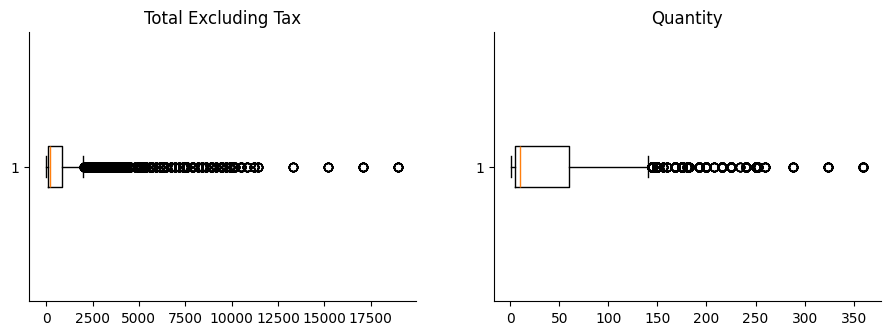

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].boxplot(col, vert=False)
ax[0].set_title("Total Excluding Tax")
ax[1].boxplot(sales_raw["Quantity"], vert=False)
ax[1].set_title("Quantity")
plt.show()

### What the AI suggested

I gave an AI tool the column list and the checks above and asked what to fix. Main points:

- Recalculate Total Excluding Tax from Total Including Tax - Tax Amount, then Unit Price = Total / Quantity (4,555 rows were rounded).
- Fill missing Delivery Date with Invoice Date + 1 day, because all other rows have 1 day.
- Fill missing Color / Brand / Size with "N/A" or "No Brand" (not every item has a color or brand).
- Keep the outliers, they are big real orders. Only cap Quantity for the models.
- Flag loss lines (negative profit) instead of deleting them.
- New columns: Delivery Days, Year, Month, Weekday and the target High Profit.

I checked each one before using it. The cleaning code is below.

## Cleaning code

In [10]:
import struct
from pathlib import Path

OUT = Path("../data/cleaned")
xl = pd.ExcelFile("../data/raw/Data.xlsx")

In [11]:
log = []  # (table, issue, rows affected, action)


def note(t, issue, n, action):
    log.append({"Table": t, "Issue": issue, "Rows Affected": int(n), "Action Taken": action})


def squeeze(s):
    return s.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()


MAX_DATE = pd.Timestamp("2099-12-31")

### DimEmployee

In [12]:
emp = xl.parse("DimEmployee")
note("DimEmployee", "Photo column 100% empty", len(emp), "Dropped column")
emp = emp.drop(columns=["Photo", "Lineage Key"])
n = emp["Preferred Name"].isna().sum()
emp["Preferred Name"] = emp["Preferred Name"].fillna("Unknown")
note("DimEmployee", "Missing Preferred Name (Unknown member)", n, "Filled with 'Unknown'")
vt = pd.to_numeric(emp["Valid To"], errors="coerce")
n = (vt >= 2958465).sum()
emp["Valid To"] = pd.to_datetime(vt.where(vt < 2958465), unit="D", origin="1899-12-30").fillna(MAX_DATE)
note("DimEmployee", "Valid To stored as Excel serial number / out-of-range date (2958466)", len(emp),
     f"Converted to Date; {n} open-ended rows set to 2099-12-31")
emp["Is Current"] = (emp["Valid To"] == MAX_DATE).astype(int)
emp["Is Salesperson"] = emp["Is Salesperson"].map({1: "Yes", 0: "No"})

### DimStockItem

In [13]:
stk = xl.parse("DimStockItem")
drop = ["Photo", "Discount", "Barcode", "Valid From", "Valid To", "Lineage Key"]
note("DimStockItem", "Photo & Discount 100% empty, Barcode 98% empty", len(stk), "Dropped columns")
note("DimStockItem", "Valid From / Valid To corrupted ('00:00.0' / '#####')", len(stk), "Dropped columns (unusable)")
stk = stk.drop(columns=drop)
for c, v in [("Color", "N/A"), ("Brand", "No Brand"), ("Size", "N/A"),
             ("Selling Package", "N/A"), ("Buying Package", "N/A")]:
    n = stk[c].isna().sum()
    stk[c] = stk[c].fillna(v)
    note("DimStockItem", f"Missing {c}", n, f"Filled with '{v}'")
stk["Recommended Retail Price"] = pd.to_numeric(
    stk["Recommended Retail Price"].astype(str).str.replace(r"[?\s,]", "", regex=True).replace("-", "0"),
    errors="coerce").fillna(0)
note("DimStockItem", "Recommended Retail Price stored as text with '? ' prefix", len(stk), "Converted to number")
n = stk["Stock Item"].str.contains(r"\s{2,}").sum()
stk["Stock Item"] = squeeze(stk["Stock Item"])
note("DimStockItem", "Extra spaces in Stock Item name", n, "Trimmed double spaces")
stk["Is Chiller Stock"] = stk["Is Chiller Stock"].map({1: "Yes", 0: "No"})

### DimCustomer

In [14]:
cus = xl.parse("DimCustomer")
note("DimCustomer", "Valid From / Valid To corrupted", len(cus), "Dropped columns")
cus = cus.drop(columns=["Valid From", "Valid To", "Lineage Key"])
cus["Credit Limit"] = pd.to_numeric(
    cus["Credit Limit"].astype(str).str.replace(r"[\s,]", "", regex=True).replace("-", None), errors="coerce")
note("DimCustomer", "Credit Limit stored as text (' 5,000.000000', ' -')", len(cus),
     "Converted to number; '-' left blank (no limit)")
cus["Postal Code"] = cus["Postal Code"].astype("Int64").astype(str).replace("<NA>", "N/A")
note("DimCustomer", "Postal Code stored as decimal (90410.0)", len(cus), "Converted to text code")
n = cus.isna().sum().sum()
for c in ["Bill To Customer", "Category", "Buying Group", "Primary Contact"]:
    cus[c] = cus[c].fillna("Unknown")
note("DimCustomer", "Missing values on Unknown member (Key 0)", 1, "Filled with 'Unknown'")

### DimCity

In [15]:
city = xl.parse("DimCity")


def wkb_point(h):
    try:
        b = bytes.fromhex(str(h)[2:])
        lat, lon = struct.unpack("<dd", b[6:22])
        return round(lat, 6), round(lon, 6)
    except Exception:
        return None, None


ll = city["Location"].map(wkb_point)
city["Latitude"] = ll.map(lambda t: t[0])
city["Longitude"] = ll.map(lambda t: t[1])
city = city.drop(columns=["Location"])
note("DimCity", "Location stored as SQL geography hex (unreadable)", len(city),
     "Decoded into Latitude / Longitude columns for maps")
n = city.duplicated(["City", "State Province"]).sum()
note("DimCity", "Same City+State appears with different City Keys (history versions)", n,
     "Kept (keys are referenced); use City+State for grouping")

### DimDate

In [16]:
dt = xl.parse("DimDate")
dt["Weekday"] = dt["Date"].dt.day_name()
dt["Quarter"] = "Q" + dt["Date"].dt.quarter.astype(str)
dt = dt.drop(columns=["Day"]) if (dt["Day"] == dt["Day Number"]).all() else dt
note("DimDate", "Duplicate column (Day = Day Number)", len(dt), "Dropped 'Day'; added Weekday & Quarter")

### FactSale

In [17]:
fs = xl.parse("FactSale")
fs["Total Excluding Tax"] = (fs["Total Including Tax"] - fs["Tax Amount"]).round(2)
n_bad = (fs["Quantity"] * fs["Unit Price"] != fs["Total Excluding Tax"]).sum()
fs["Unit Price"] = (fs["Total Excluding Tax"] / fs["Quantity"]).round(2)
note("FactSale", "Unit Price & Total Excluding Tax rounded to whole numbers (Qty x Price != Total)", n_bad,
     "Recalculated: Total Excl Tax = Total Incl Tax - Tax Amount; Unit Price = Total Excl Tax / Quantity")
n = fs["Delivery Date Key"].isna().sum()
fs["Delivery Date Key"] = fs["Delivery Date Key"].fillna(fs["Invoice Date Key"] + pd.Timedelta(days=1))
note("FactSale", "Missing Delivery Date", n, "Filled with Invoice Date + 1 day (all other rows have 1-day lag)")
n = fs["Description"].str.contains(r"\s{2,}").sum()
fs["Description"] = squeeze(fs["Description"])
note("FactSale", "Extra spaces in Description", n, "Trimmed double spaces")
note("FactSale", "Lineage Key constant (11) - no information", len(fs), "Dropped column")
fs = fs.drop(columns=["Lineage Key"])
note("FactSale", "Duplicate rows", fs.drop(columns="Sale Key").duplicated().sum(), "None found")
note("FactSale", "Orphan foreign keys", 0, "Checked City/Customer/Stock/Employee/Date keys - all valid")
note("FactSale", "Negative Profit (loss-making lines)", (fs["Profit"] < 0).sum(),
     "Kept (real business data); flagged in 'Is Loss' column")
fs["Profit Margin %"] = (fs["Profit"] / fs["Total Excluding Tax"] * 100).round(2)
fs["Is Loss"] = (fs["Profit"] < 0).map({True: "Yes", False: "No"})
q1, q3 = fs["Total Excluding Tax"].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
fs["Is Outlier"] = (fs["Total Excluding Tax"] > upper).map({True: "Yes", False: "No"})
note("FactSale", f"Outliers in Total Excluding Tax (IQR rule, > {upper:,.0f})",
     (fs["Is Outlier"] == "Yes").sum(), "Kept (large genuine orders); flagged in 'Is Outlier' column")
z = (fs["Quantity"] - fs["Quantity"].mean()) / fs["Quantity"].std()
note("FactSale", "Outliers in Quantity (Z-score > 3)", (z.abs() > 3).sum(),
     "Kept (real orders); capped only in the model data")

# new columns
fs["Delivery Days"] = (fs["Delivery Date Key"] - fs["Invoice Date Key"]).dt.days
fs["Year"] = fs["Invoice Date Key"].dt.year
fs["Month"] = fs["Invoice Date Key"].dt.month
fs["Weekday"] = fs["Invoice Date Key"].dt.day_name()
median_profit = fs["Profit"].median()
fs["High Profit"] = (fs["Profit"] > median_profit).map({True: "Yes", False: "No"})
note("FactSale", "Feature engineering", len(fs),
     f"Added Delivery Days, Year, Month, Weekday and target High Profit (Profit > median {median_profit:.0f})")

### Save cleaned workbook

In [18]:
tables = {"FactSale": fs, "DimDate": dt, "DimCustomer": cus, "DimStockItem": stk,
          "DimEmployee": emp, "DimCity": city}
logdf = pd.DataFrame(log)
with pd.ExcelWriter(OUT / "Cleaned_Data.xlsx", engine="openpyxl", datetime_format="yyyy-mm-dd") as w:
    logdf.to_excel(w, "Cleaning Log", index=False)
    for k, v in tables.items():
        v.to_excel(w, k, index=False)
    for ws in w.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        for col in ws.columns:
            width = max(len(str(c.value or "")) for c in list(col)[:200])
            ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 60)

C:\Users\Ibrahim\AppData\Local\Temp\ipykernel_18044\327164031.py:5: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  logdf.to_excel(w, "Cleaning Log", index=False)
C:\Users\Ibrahim\AppData\Local\Temp\ipykernel_18044\327164031.py:7: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  v.to_excel(w, k, index=False)


### one flat table for the models

In [19]:
m = (fs.merge(stk[["Stock Item Key", "Color", "Brand", "Size", "Is Chiller Stock", "Lead Time Days",
                   "Typical Weight Per Unit"]], on="Stock Item Key", how="left")
       .merge(cus[["Customer Key", "Buying Group", "Category"]], on="Customer Key", how="left")
       .merge(city[["City Key", "State Province", "Sales Territory"]], on="City Key", how="left")
       .merge(emp[["Employee Key", "Employee"]], left_on="Salesperson Key", right_on="Employee Key", how="left"))
m = m[["Sale Key", "Invoice Date Key", "Description", "Package", "Quantity", "Unit Price", "Tax Rate",
       "Color", "Brand", "Size", "Is Chiller Stock", "Lead Time Days", "Typical Weight Per Unit",
       "Buying Group", "Category", "State Province", "Sales Territory", "Employee",
       "Year", "Month", "Weekday", "Total Excluding Tax", "Profit", "High Profit"]]
m.to_csv(OUT / "sales_model.csv", index=False)

## Cleaned data

In [20]:
log = pd.read_excel("../data/cleaned/Cleaned_Data.xlsx", sheet_name="Cleaning Log")
log[["Table", "Issue", "Rows Affected", "Action Taken"]]

,Table,Issue,Rows Affected,Action Taken
0,DimEmployee,Photo column 100% empty,212,Dropped column
1,DimEmployee,Missing Preferred Name (Unknown member),1,Filled with 'Unknown'
2,DimEmployee,Valid To stored as Excel serial number / out-o...,212,Converted to Date; 19 open-ended rows set to 2...
3,DimStockItem,"Photo & Discount 100% empty, Barcode 98% empty",672,Dropped columns
4,DimStockItem,Valid From / Valid To corrupted ('00:00.0' / '...,672,Dropped columns (unusable)
5,DimStockItem,Missing Color,312,Filled with 'N/A'
6,DimStockItem,Missing Brand,605,Filled with 'No Brand'
7,DimStockItem,Missing Size,204,Filled with 'N/A'
8,DimStockItem,Missing Selling Package,1,Filled with 'N/A'
9,DimStockItem,Missing Buying Package,1,Filled with 'N/A'


In [21]:
df = pd.read_csv("../data/cleaned/sales_model.csv", keep_default_na=False, na_values=[""],
                 parse_dates=["Invoice Date Key"])
print(df.shape)
print("missing:", df.isnull().sum().sum())
df.head()

(26397, 24)
missing: 0


,Sale Key,Invoice Date Key,Description,Package,Quantity,Unit Price,Tax Rate,Color,Brand,Size,...,Category,State Province,Sales Territory,Employee,Year,Month,Weekday,Total Excluding Tax,Profit,High Profit
0,49265,2013-10-22,DBA joke mug - mind if I join you? (White),Each,6,13.0,15,White,No Brand,N/A,...,Unknown,California,Far West,Amy Trefl,2013,10,Tuesday,78.0,51.0,No
1,49372,2013-10-22,Developer joke mug - a foo walks into a bar (B...,Each,6,13.0,15,Black,No Brand,N/A,...,Unknown,California,Far West,Amy Trefl,2013,10,Tuesday,78.0,51.0,No
2,50379,2013-10-28,Developer joke mug - a foo walks into a bar (W...,Each,6,13.0,15,White,No Brand,N/A,...,Unknown,Washington,Far West,Sophia Hinton,2013,10,Monday,78.0,51.0,No
3,51852,2013-11-06,Developer joke mug - this code was generated b...,Each,6,13.0,15,Black,No Brand,N/A,...,Unknown,California,Far West,Taj Shand,2013,11,Wednesday,78.0,51.0,No
4,52374,2013-11-08,DBA joke mug - mind if I join you? (Black),Each,6,13.0,15,Black,No Brand,N/A,...,Unknown,Oregon,Far West,Jack Potter,2013,11,Friday,78.0,51.0,No


## EDA

In [22]:
revenue = df["Total Excluding Tax"].sum()
profit = df["Profit"].sum()
print("Revenue:", round(revenue))
print("Profit:", round(profit))
print("Margin %:", round(profit / revenue * 100, 1))

Revenue: 19879593
Profit: 9923892
Margin %: 49.9


In [23]:
df[['Quantity', 'Unit Price', 'Total Excluding Tax', 'Profit']].describe().round(1)

,Quantity,Unit Price,Total Excluding Tax,Profit
count,26397.0,26397.0,26397.0,26397.0
mean,39.0,44.8,753.1,375.9
std,54.1,135.2,1444.9,762.0
min,1.0,0.7,3.2,-645.0
25%,5.0,13.0,96.0,50.4
50%,10.0,18.0,226.8,120.0
75%,60.0,32.0,864.0,390.0
max,360.0,1899.0,18990.0,9200.0


### Histogram

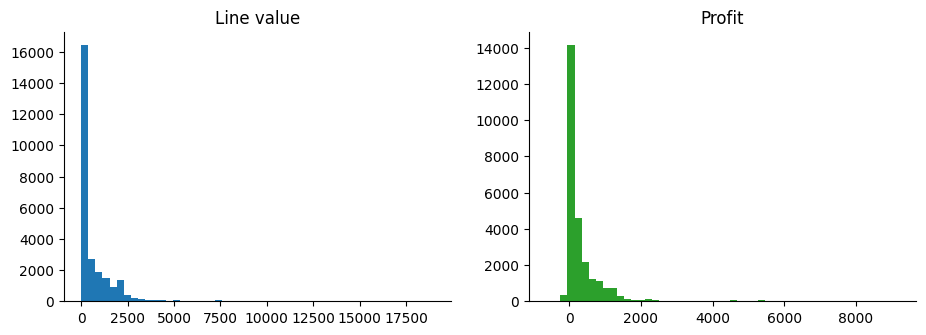

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df["Total Excluding Tax"], bins=50)
ax[0].set_title("Line value")
ax[1].hist(df["Profit"], bins=50, color="tab:green")
ax[1].set_title("Profit")
plt.savefig("../images/charts/hist.png", bbox_inches="tight")
plt.show()

Both are right skewed. Most lines are small and a few are very big.

### Line chart - monthly sales

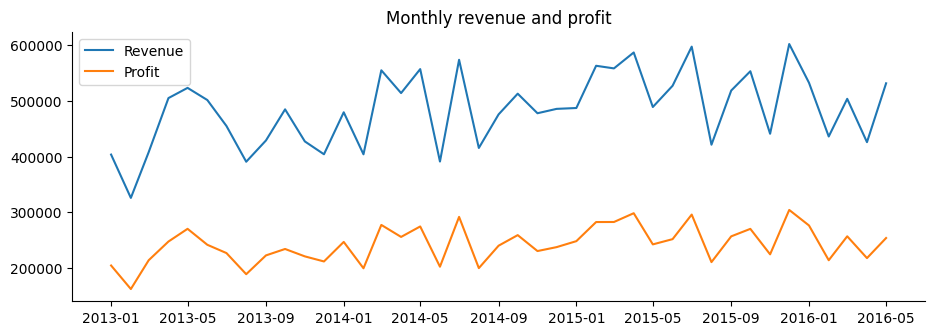

In [25]:
monthly = df.groupby(df["Invoice Date Key"].dt.to_period("M"))[["Total Excluding Tax", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(11, 3.5))
plt.plot(monthly.index, monthly["Total Excluding Tax"], label="Revenue")
plt.plot(monthly.index, monthly["Profit"], label="Profit")
plt.legend()
plt.title("Monthly revenue and profit")
plt.savefig("../images/charts/monthly.png", bbox_inches="tight")
plt.show()

In [26]:
df.groupby('Year')['Total Excluding Tax'].sum().round()

Year
2013    5257955.0
2014    5843423.0
2015    6347855.0
2016    2430360.0
Name: Total Excluding Tax, dtype: float64

### Bar charts

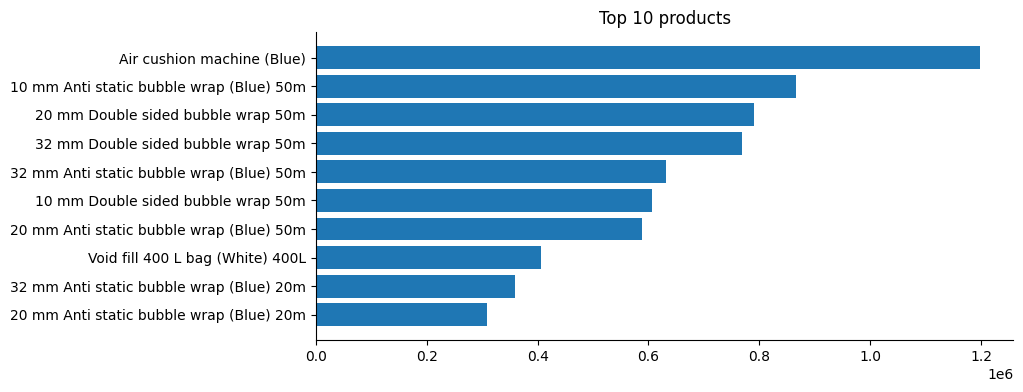

In [27]:
top = df.groupby("Description")["Total Excluding Tax"].sum().nlargest(10).sort_values()
plt.figure(figsize=(9, 4))
plt.barh([d[:40] for d in top.index], top)
plt.title("Top 10 products")
plt.savefig("../images/charts/top_products.png", bbox_inches="tight")
plt.show()

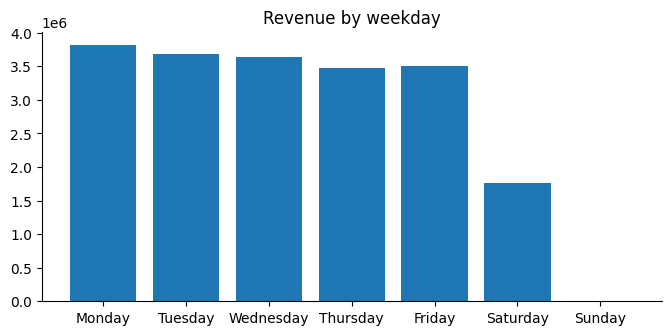

In [28]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df.groupby("Weekday")["Total Excluding Tax"].sum().reindex(days).fillna(0)
plt.figure(figsize=(8, 3.5))
plt.bar(wd.index, wd)
plt.title("Revenue by weekday")
plt.savefig("../images/charts/weekday.png", bbox_inches="tight")
plt.show()

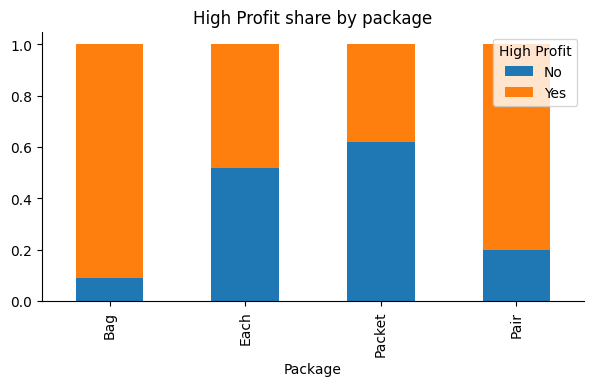

High Profit,No,Yes
Package,,
Bag,0.09,0.91
Each,0.52,0.48
Packet,0.62,0.38
Pair,0.20,0.80


In [29]:
hp = pd.crosstab(df["Package"], df["High Profit"], normalize="index").round(2)
hp.plot(kind="bar", stacked=True, figsize=(7, 3.5), title="High Profit share by package")
plt.savefig("../images/charts/package_target.png", bbox_inches="tight")
plt.show()
hp

### Scatter

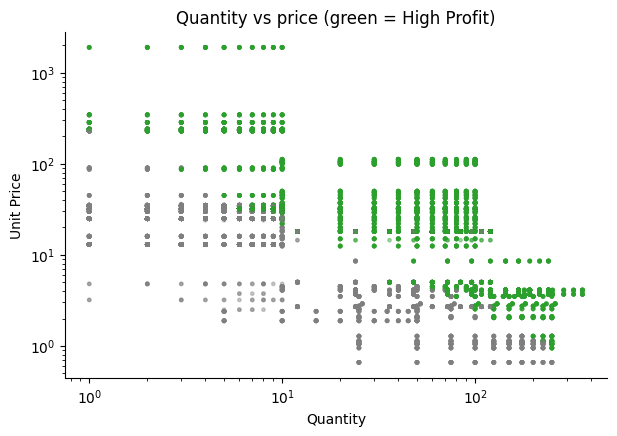

In [30]:
plt.figure(figsize=(7, 4.5))
colors = df["High Profit"].map({"Yes": "tab:green", "No": "tab:gray"})
plt.scatter(df["Quantity"], df["Unit Price"], c=colors, s=6, alpha=.4)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.title("Quantity vs price (green = High Profit)")
plt.savefig("../images/charts/scatter.png", bbox_inches="tight")
plt.show()

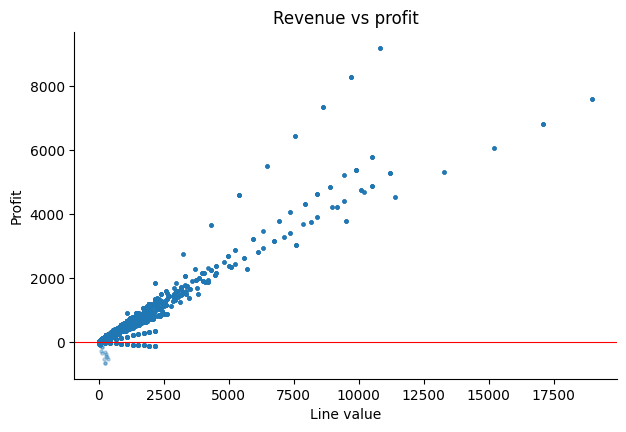

In [31]:
plt.figure(figsize=(7, 4.5))
plt.scatter(df["Total Excluding Tax"], df["Profit"], s=5, alpha=.3)
plt.axhline(0, color="red", lw=.8)
plt.xlabel("Line value")
plt.ylabel("Profit")
plt.title("Revenue vs profit")
plt.show()

### Correlation

In [32]:
df[['Quantity', 'Unit Price', 'Lead Time Days', 'Typical Weight Per Unit', 'Total Excluding Tax', 'Profit']].corr().round(2)

,Quantity,Unit Price,Lead Time Days,Typical Weight Per Unit,Total Excluding Tax,Profit
Quantity,1.00,-0.14,0.03,-0.09,0.24,0.23
Unit Price,-0.14,1.00,0.26,0.49,0.52,0.41
Lead Time Days,0.03,0.26,1.00,0.29,0.14,0.10
Typical Weight Per Unit,-0.09,0.49,0.29,1.00,0.46,0.43
Total Excluding Tax,0.24,0.52,0.14,0.46,1.00,0.95
Profit,0.23,0.41,0.10,0.43,0.95,1.00


### Groups

In [33]:
df.groupby('Buying Group')[['Total Excluding Tax', 'Profit']].sum().round()

,Total Excluding Tax,Profit
Buying Group,,
Tailspin Toys,8057346.0,3975493.0
Unknown,6768716.0,3428607.0
Wingtip Toys,5053531.0,2519792.0


In [34]:
df.groupby('State Province')['Total Excluding Tax'].sum().sort_values(ascending=False).round()

State Province
California    8831110.0
Washington    4227224.0
Alaska        3002071.0
Oregon        2251100.0
Nevada        1251230.0
Hawaii         316858.0
Name: Total Excluding Tax, dtype: float64

In [35]:
df.groupby('Employee')['Total Excluding Tax'].sum().sort_values(ascending=False).round()

Employee
Sophia Hinton         2219628.0
Lily Code             2112719.0
Kayla Woodcock        2081323.0
Taj Shand             2008877.0
Archer Lamble         2005034.0
Hudson Hollinworth    1983752.0
Hudson Onslow         1915478.0
Amy Trefl             1890399.0
Anthony Grosse        1873638.0
Jack Potter           1788746.0
Name: Total Excluding Tax, dtype: float64

In [36]:
df[df['Profit'] < 0].groupby('Description')['Profit'].sum().nsmallest(5).round()

Description
Halloween zombie mask (Light Brown) M                  -9024.0
Halloween zombie mask (Light Brown) S                  -8904.0
Halloween zombie mask (Light Brown) XL                 -7884.0
Halloween zombie mask (Light Brown) L                  -7248.0
USB food flash drive - dim sum 10 drive variety pack   -3212.0
Name: Profit, dtype: float64

## What I found

- Sales grow every year (2016 has only Jan - May).
- Nobody buys on Sunday.
- Packaging items (tape, boxes) bring the most money.
- Profit goes up with line value (strong correlation), so bigger orders = more profit.
- Some items always lose money (Halloween masks are the top one).